<a href="https://colab.research.google.com/github/robyke/plp-da-a4-student-eda-and-board-report/blob/main/board_report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# One-Page Visual Report for the Duka Electronics Board

This notebook creates a one-page visual report for the Duka Electronics board using H1 2026 sales data. The report focuses on branch performance, monthly revenue trends, product performance and where management should focus in the second half of the year.

## Storyboard

### Audience

The audience is the Duka Electronics board and CEO. They need a quick, clear view of H1 2026 sales performance before deciding where to focus management attention and marketing resources in H2.

### Decision

The board needs to decide which branches and areas of the business should receive the most attention in the second half of 2026.

### Big Idea

Nairobi drives about 36% of revenue, but Q2 momentum has shifted: Eldoret grew strongly while Mombasa and Nakuru declined by about a quarter. H2 attention should prioritise recovering Mombasa and Nakuru while protecting growth in Eldoret and Kisumu.

### Situation

Duka Electronics generated strong H1 revenue, led by Nairobi, which remained the largest branch by total revenue.

### Complication

Performance was uneven across branches. Eldoret and Kisumu improved in Q2, while Mombasa and Nakuru declined sharply compared with Q1.

### Resolution

The board should prioritise recovery actions in Mombasa and Nakuru while maintaining support for branches showing positive momentum.

In [1]:
%cd /content/plp-da-a4-student-eda-and-board-report

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Recreate the raw files if this Colab runtime was restarted
if not os.path.exists("duka_sales.csv"):
    !python generate_data.py

sales = pd.read_csv(
    "duka_sales.csv",
    parse_dates=["order_date"]
)

sales["revenue"] = sales["quantity"] * sales["unit_price"]

print("Rows:", len(sales))
print("Total revenue: KES {:,.0f}".format(sales["revenue"].sum()))
print(
    "Date range:",
    sales["order_date"].min().date(),
    "to",
    sales["order_date"].max().date()
)

display(sales.head())

[Errno 2] No such file or directory: '/content/plp-da-a4-student-eda-and-board-report'
/content
python3: can't open file '/content/generate_data.py': [Errno 2] No such file or directory


FileNotFoundError: [Errno 2] No such file or directory: 'duka_sales.csv'

In [2]:
!git clone https://github.com/robyke/plp-da-a4-student-eda-and-board-report.git
%cd /content/plp-da-a4-student-eda-and-board-report
!ls

Cloning into 'plp-da-a4-student-eda-and-board-report'...
remote: Enumerating objects: 14, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 14 (delta 2), reused 11 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (14/14), 268.23 KiB | 1.40 MiB/s, done.
Resolving deltas: 100% (2/2), done.
/content/plp-da-a4-student-eda-and-board-report
figures  generate_data.py  requirements.txt  student_eda.ipynb


In [3]:
!python generate_data.py

Created student_performance.csv
Created duka_sales.csv


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sales = pd.read_csv(
    "duka_sales.csv",
    parse_dates=["order_date"]
)

sales["revenue"] = sales["quantity"] * sales["unit_price"]

print("Rows:", len(sales))
print("Total revenue: KES {:,.0f}".format(sales["revenue"].sum()))
print(
    "Date range:",
    sales["order_date"].min().date(),
    "to",
    sales["order_date"].max().date()
)

display(sales.head())

Rows: 1000
Total revenue: KES 71,792,500
Date range: 2026-01-01 to 2026-06-29


,order_id,order_date,branch,product,quantity,channel,unit_price,revenue
0,1001,2026-06-03,Nakuru,Phone,3,In-store,15000,45000
1,1002,2026-02-02,Nairobi,Laptop,4,In-store,65000,260000
2,1003,2026-01-05,Nakuru,Tablet,5,In-store,28000,140000
3,1004,2026-04-26,Nairobi,Headphones,5,In-store,2500,12500
4,1005,2026-03-07,Nairobi,Headphones,3,In-store,2500,7500


## Before-and-After Chart Makeover

This section compares a basic default chart with a redesigned chart that is easier for board members to understand quickly. Both charts show total revenue by product.

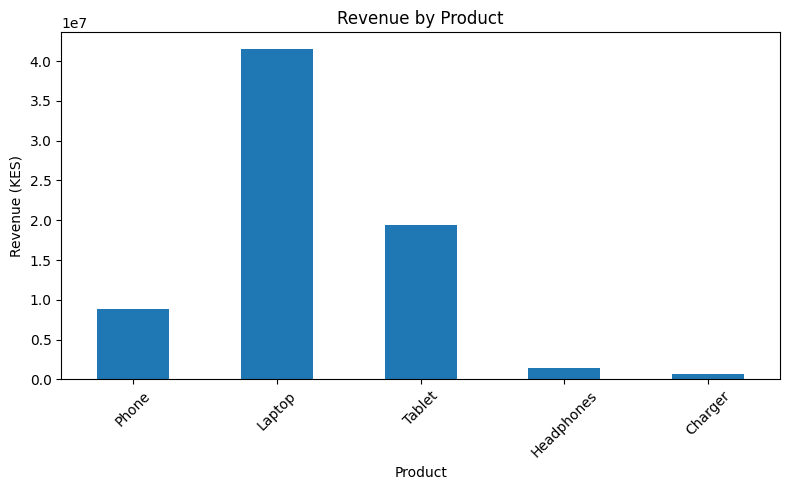

Saved: figures/before.png


In [5]:
import os

os.makedirs("figures", exist_ok=True)

product_before = (
    sales.groupby("product", sort=False)["revenue"]
    .sum()
)

fig, ax = plt.subplots(figsize=(8, 5))

product_before.plot(
    kind="bar",
    ax=ax,
    title="Revenue by Product"
)

ax.set_xlabel("Product")
ax.set_ylabel("Revenue (KES)")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("figures/before.png", dpi=150)
plt.show()

print("Saved: figures/before.png")

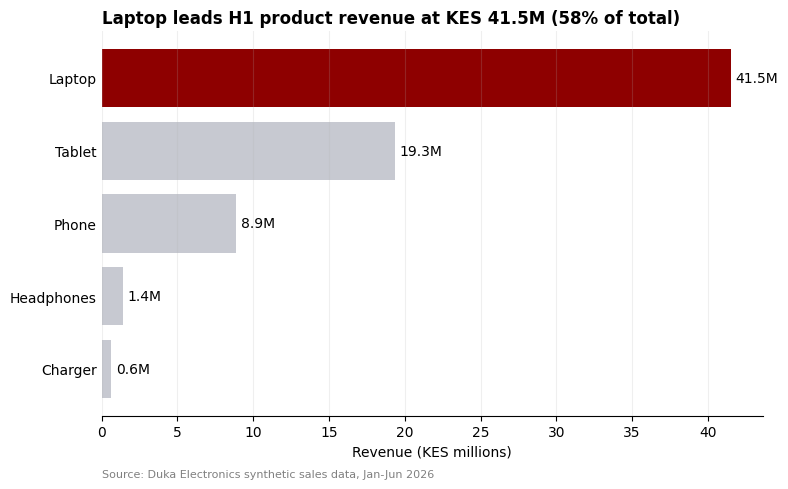

Saved: figures/after.png


In [6]:
product_after = (
    sales.groupby("product")["revenue"]
    .sum()
    .sort_values()
)

top_product = product_after.idxmax()
top_revenue = product_after.max()
total_revenue = product_after.sum()

top_share = top_revenue / total_revenue * 100

colors = [
    "#8E0000" if product == top_product else "#C7C9D1"
    for product in product_after.index
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.barh(
    product_after.index,
    product_after.values / 1e6,
    color=colors
)

ax.set_title(
    f"{top_product} leads H1 product revenue at KES {top_revenue/1e6:.1f}M "
    f"({top_share:.0f}% of total)",
    loc="left",
    fontweight="bold"
)

ax.set_xlabel("Revenue (KES millions)")
ax.set_ylabel("")

ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", alpha=0.2)

for bar, value in zip(bars, product_after.values):
    ax.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{value/1e6:.1f}M",
        va="center"
    )

ax.text(
    0,
    -0.16,
    "Source: Duka Electronics synthetic sales data, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=8,
    color="grey"
)

plt.tight_layout()
plt.savefig("figures/after.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved: figures/after.png")

### Before-and-After Design Changes

The original chart uses a generic title, unsorted vertical bars and no direct value labels, so the main message is not immediately clear.

The redesigned chart makes several improvements:

- The products are sorted by revenue to make comparison easier.
- Horizontal bars make the product names easier to read.
- The highest-revenue product is highlighted in PLP redberry (`#8E0000`), while the other products are grey to reduce unnecessary colour.
- Direct revenue labels allow the board to read values without estimating from the axis.
- The generic title is replaced with an insight title that states the main finding.
- Unnecessary chart borders are removed to reduce clutter.
- A source and time-period line is added for context.

These changes make the main finding easier to understand quickly, especially for board members reading the report on a phone.

In [7]:
!ls -lh figures/before.png figures/after.png

-rw-r--r-- 1 root root 48K Nov 17 01:21 figures/after.png
-rw-r--r-- 1 root root 41K Nov 17 01:21 figures/before.png


## Q1 vs Q2 Branch Performance

To understand where H2 attention should go, this section compares each branch's revenue in Q1 and Q2. The goal is to identify which branches gained momentum and which branches weakened during the first half of 2026.

In [8]:
sales["quarter"] = np.where(
    sales["order_date"].dt.month <= 3,
    "Q1",
    "Q2"
)

quarter_branch = pd.pivot_table(
    sales,
    index="branch",
    columns="quarter",
    values="revenue",
    aggfunc="sum"
)

quarter_branch["change_pct"] = (
    (quarter_branch["Q2"] / quarter_branch["Q1"] - 1) * 100
)

quarter_branch = quarter_branch.sort_values("change_pct")

display(
    quarter_branch.assign(
        Q1_M=lambda x: (x["Q1"] / 1e6).round(2),
        Q2_M=lambda x: (x["Q2"] / 1e6).round(2),
        Change_pct=lambda x: x["change_pct"].round(1)
    )[["Q1_M", "Q2_M", "Change_pct"]]
)

quarter,Q1_M,Q2_M,Change_pct
branch,,,
Nakuru,6.90,5.07,-26.5
Mombasa,8.02,5.98,-25.5
Nairobi,12.48,13.62,9.1
Kisumu,5.01,5.86,17.0
Eldoret,3.54,5.31,49.9


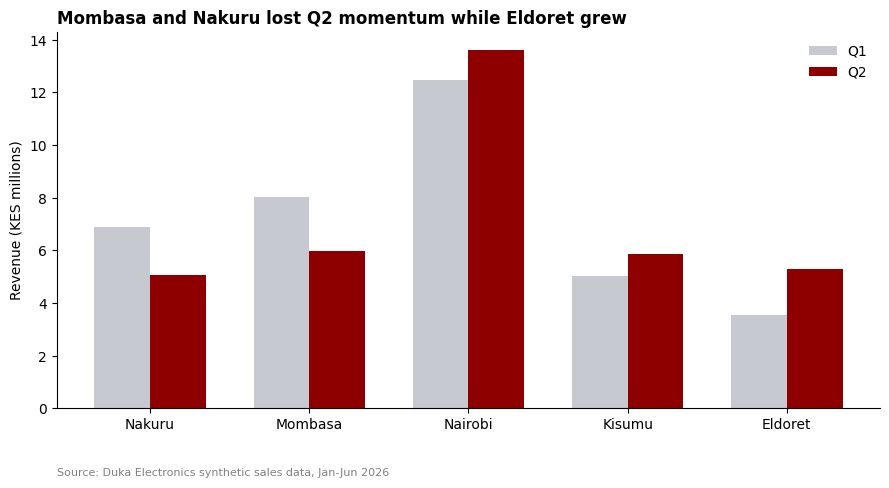

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(quarter_branch))
width = 0.35

ax.bar(
    x - width / 2,
    quarter_branch["Q1"] / 1e6,
    width,
    label="Q1",
    color="#C7C9D1"
)

ax.bar(
    x + width / 2,
    quarter_branch["Q2"] / 1e6,
    width,
    label="Q2",
    color="#8E0000"
)

ax.set_xticks(x)
ax.set_xticklabels(quarter_branch.index)

ax.set_ylabel("Revenue (KES millions)")

ax.set_title(
    "Mombasa and Nakuru lost Q2 momentum while Eldoret grew",
    loc="left",
    fontweight="bold"
)

ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

ax.text(
    0,
    -0.18,
    "Source: Duka Electronics synthetic sales data, Jan-Jun 2026",
    transform=ax.transAxes,
    fontsize=8,
    color="grey"
)

plt.tight_layout()
plt.show()

### Q1 vs Q2 Findings

Branch momentum changed significantly between Q1 and Q2. Nakuru and Mombasa recorded clear declines, while Eldoret showed the strongest improvement. Nairobi also grew and remained the largest branch by revenue. This pattern supports an H2 strategy that focuses recovery efforts on Nakuru and Mombasa while protecting growth in Eldoret, Kisumu and Nairobi.

In [10]:
monthly = (
    sales.set_index("order_date")
    .resample("MS")["revenue"]
    .sum()
)

branch_rev = (
    sales.groupby("branch")["revenue"]
    .sum()
    .sort_values()
)

product_rev = (
    sales.groupby("product")["revenue"]
    .sum()
    .sort_values()
)

channel_rev = (
    sales.groupby("channel")["revenue"]
    .sum()
    .sort_values()
)

print("Monthly revenue:")
display((monthly / 1e6).round(2).rename("KES millions"))

print("\nBranch revenue:")
display((branch_rev / 1e6).round(2).rename("KES millions"))

print("\nProduct revenue:")
display((product_rev / 1e6).round(2).rename("KES millions"))

print("\nChannel revenue:")
display((channel_rev / 1e6).round(2).rename("KES millions"))

Monthly revenue:


,KES millions
order_date,
2026-01-01,11.79
2026-02-01,11.77
2026-03-01,12.40
2026-04-01,13.52
2026-05-01,11.42
2026-06-01,10.90



Branch revenue:


,KES millions
branch,
Eldoret,8.84
Kisumu,10.87
Nakuru,11.97
Mombasa,14.00
Nairobi,26.11



Product revenue:


,KES millions
product,
Charger,0.64
Headphones,1.39
Phone,8.88
Tablet,19.35
Laptop,41.54



Channel revenue:


,KES millions
channel,
Phone order,8.04
Online,22.79
In-store,40.97


## Final One-Page Board Report

The final report combines five views: monthly revenue trend, branch revenue, product revenue, channel revenue and Q1 vs Q2 branch performance. Each chart uses an insight title, labelled units and a source line.

/tmp/ipykernel_941/616458525.py:303: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.93])


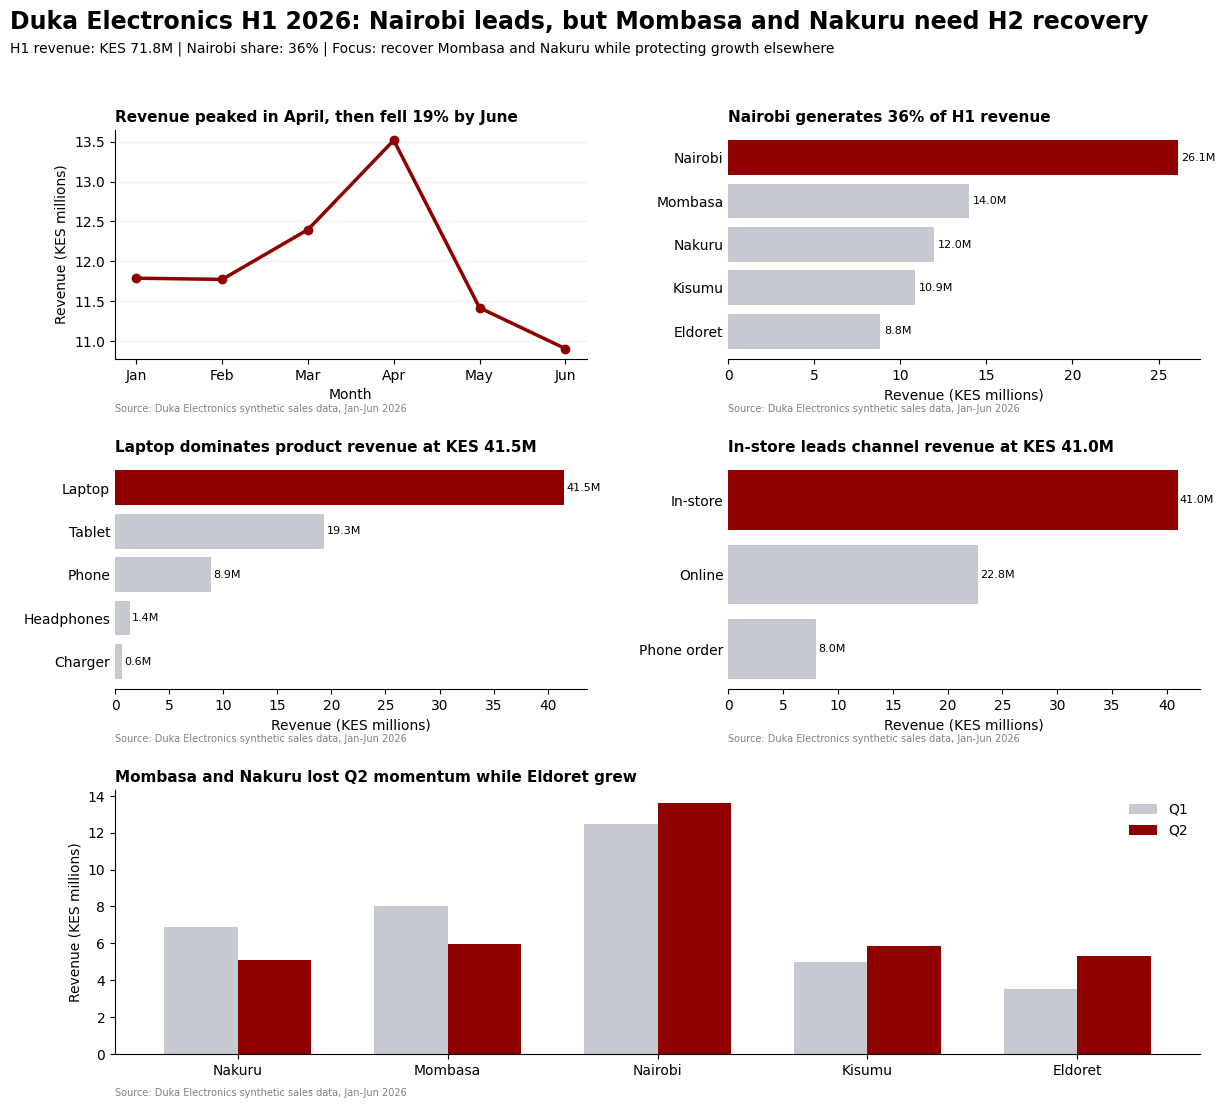

Saved: reports/duka_board_report.png


In [11]:
import os

os.makedirs("reports", exist_ok=True)

# -----------------------------
# Summary calculations
# -----------------------------

total_revenue = sales["revenue"].sum()

nairobi_revenue = (
    sales.loc[sales["branch"] == "Nairobi", "revenue"].sum()
)

nairobi_share = (
    nairobi_revenue / total_revenue * 100
)

peak_month = monthly.idxmax()
peak_revenue = monthly.max()

june_revenue = monthly.iloc[-1]

peak_to_june_drop = (
    (june_revenue / peak_revenue - 1) * 100
)

top_product = product_rev.idxmax()
top_product_revenue = product_rev.max()

top_channel = channel_rev.idxmax()
top_channel_revenue = channel_rev.max()

# -----------------------------
# One-page report canvas
# -----------------------------

fig = plt.figure(figsize=(14, 12))

gs = fig.add_gridspec(
    3,
    2,
    height_ratios=[1, 1, 1.15],
    hspace=0.42,
    wspace=0.30
)

fig.suptitle(
    "Duka Electronics H1 2026: Nairobi leads, but Mombasa and Nakuru need H2 recovery",
    fontsize=17,
    fontweight="bold",
    x=0.05,
    ha="left",
    y=0.98
)

fig.text(
    0.05,
    0.945,
    f"H1 revenue: KES {total_revenue/1e6:.1f}M | "
    f"Nairobi share: {nairobi_share:.0f}% | "
    f"Focus: recover Mombasa and Nakuru while protecting growth elsewhere",
    fontsize=10
)

source_text = "Source: Duka Electronics synthetic sales data, Jan-Jun 2026"

# -----------------------------
# Chart 1: Monthly revenue
# -----------------------------

ax = fig.add_subplot(gs[0, 0])

month_labels = monthly.index.strftime("%b")

ax.plot(
    month_labels,
    monthly.values / 1e6,
    marker="o",
    linewidth=2.5,
    color="#8E0000"
)

ax.set_title(
    f"Revenue peaked in {peak_month:%B}, then fell {abs(peak_to_june_drop):.0f}% by June",
    loc="left",
    fontweight="bold",
    fontsize=11
)

ax.set_ylabel("Revenue (KES millions)")
ax.set_xlabel("Month")

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)

ax.text(
    0,
    -0.23,
    source_text,
    transform=ax.transAxes,
    fontsize=7,
    color="grey"
)

# -----------------------------
# Chart 2: Branch revenue
# -----------------------------

ax = fig.add_subplot(gs[0, 1])

branch_colors = [
    "#8E0000" if branch == "Nairobi" else "#C7C9D1"
    for branch in branch_rev.index
]

bars = ax.barh(
    branch_rev.index,
    branch_rev.values / 1e6,
    color=branch_colors
)

ax.set_title(
    f"Nairobi generates {nairobi_share:.0f}% of H1 revenue",
    loc="left",
    fontweight="bold",
    fontsize=11
)

ax.set_xlabel("Revenue (KES millions)")
ax.set_ylabel("")

ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)

for bar, value in zip(bars, branch_rev.values):
    ax.text(
        bar.get_width() + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{value/1e6:.1f}M",
        va="center",
        fontsize=8
    )

ax.text(
    0,
    -0.23,
    source_text,
    transform=ax.transAxes,
    fontsize=7,
    color="grey"
)

# -----------------------------
# Chart 3: Product revenue
# -----------------------------

ax = fig.add_subplot(gs[1, 0])

product_colors = [
    "#8E0000" if product == top_product else "#C7C9D1"
    for product in product_rev.index
]

bars = ax.barh(
    product_rev.index,
    product_rev.values / 1e6,
    color=product_colors
)

ax.set_title(
    f"{top_product} dominates product revenue at KES {top_product_revenue/1e6:.1f}M",
    loc="left",
    fontweight="bold",
    fontsize=11
)

ax.set_xlabel("Revenue (KES millions)")
ax.set_ylabel("")

ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)

for bar, value in zip(bars, product_rev.values):
    ax.text(
        bar.get_width() + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{value/1e6:.1f}M",
        va="center",
        fontsize=8
    )

ax.text(
    0,
    -0.23,
    source_text,
    transform=ax.transAxes,
    fontsize=7,
    color="grey"
)

# -----------------------------
# Chart 4: Channel revenue
# -----------------------------

ax = fig.add_subplot(gs[1, 1])

channel_colors = [
    "#8E0000" if channel == top_channel else "#C7C9D1"
    for channel in channel_rev.index
]

bars = ax.barh(
    channel_rev.index,
    channel_rev.values / 1e6,
    color=channel_colors
)

ax.set_title(
    f"{top_channel} leads channel revenue at KES {top_channel_revenue/1e6:.1f}M",
    loc="left",
    fontweight="bold",
    fontsize=11
)

ax.set_xlabel("Revenue (KES millions)")
ax.set_ylabel("")

ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)

for bar, value in zip(bars, channel_rev.values):
    ax.text(
        bar.get_width() + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{value/1e6:.1f}M",
        va="center",
        fontsize=8
    )

ax.text(
    0,
    -0.23,
    source_text,
    transform=ax.transAxes,
    fontsize=7,
    color="grey"
)

# -----------------------------
# Chart 5: Q1 vs Q2 branch performance
# -----------------------------

ax = fig.add_subplot(gs[2, :])

x = np.arange(len(quarter_branch))
width = 0.35

ax.bar(
    x - width / 2,
    quarter_branch["Q1"] / 1e6,
    width,
    label="Q1",
    color="#C7C9D1"
)

ax.bar(
    x + width / 2,
    quarter_branch["Q2"] / 1e6,
    width,
    label="Q2",
    color="#8E0000"
)

ax.set_xticks(x)
ax.set_xticklabels(quarter_branch.index)

ax.set_ylabel("Revenue (KES millions)")

ax.set_title(
    "Mombasa and Nakuru lost Q2 momentum while Eldoret grew",
    loc="left",
    fontweight="bold",
    fontsize=11
)

ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

ax.text(
    0,
    -0.16,
    source_text,
    transform=ax.transAxes,
    fontsize=7,
    color="grey"
)

# -----------------------------
# Export
# -----------------------------

plt.tight_layout(rect=[0, 0, 1, 0.93])

plt.savefig(
    "reports/duka_board_report.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved: reports/duka_board_report.png")

In [12]:
!ls -lh reports/duka_board_report.png

-rw-r--r-- 1 root root 298K Nov 17 01:26 reports/duka_board_report.png


## Board Report Conclusion

Duka Electronics generated KES 71.8 million in H1 2026. Nairobi remained the largest branch, contributing about 36% of total revenue. Monthly revenue peaked in April and then weakened in May and June. Laptop sales generated the most product revenue, while In-store remained the strongest sales channel.

The most important branch-level change is the shift in Q2 momentum. Eldoret improved strongly, while Mombasa and Nakuru declined compared with Q1. The recommended H2 focus is therefore to prioritise recovery actions in Mombasa and Nakuru while maintaining support for Nairobi, Eldoret and Kisumu.